# Heart Disease Prediction from Multi-Hospital Clinical Data

**Goal:** predict whether a patient has heart disease from routine clinical measurements, after cleaning messy real-world data from four hospitals, then compare two models and check whether a model trained at some hospitals works at another.

**Data:** Heart Disease dataset, UCI Machine Learning Repository (Kaggle file `heart_disease_uci.csv`). 920 patients referred for coronary angiography at four sites: Cleveland (USA), Hungary, Switzerland and VA Long Beach (USA), collected in the 1980s.

**Why recall matters:** missing a patient who has heart disease (false negative) is worse than a false alarm, which only leads to more tests. So we track **recall for disease** alongside accuracy.

Run each cell in order with **Shift + Enter**.

## 1. Import libraries

In [1]:
import os
from sklearn.base import clone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)
RANDOM_STATE = 42

## 2. Load the data

**ACTION:** upload `heart_disease_uci.csv` into Colab: click the folder icon on the left and drag the file in, or run the cell and choose the file when asked.

In [2]:
FILE = "heart_disease_uci.csv"

if not os.path.exists(FILE):
    from google.colab import files
    uploaded = files.upload()          # a "Choose files" button appears
    FILE = list(uploaded.keys())[0]

df = pd.read_csv(FILE)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


**What each column means**

| Column | Meaning |
|---|---|
| age | Age in years |
| sex | Male / Female |
| dataset | Hospital the patient came from |
| cp | Chest pain type: typical angina, atypical angina, non-anginal, asymptomatic |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (TRUE/FALSE) |
| restecg | Resting ECG result: normal, ST-T abnormality, LV hypertrophy |
| thalch | Maximum heart rate reached during exercise test |
| exang | Chest pain caused by exercise (TRUE/FALSE) |
| oldpeak | ST depression on ECG during exercise compared with rest |
| slope | Slope of the ST segment at peak exercise |
| ca | Number of major vessels coloured by fluoroscopy (0–3) |
| thal | Thallium stress test result |
| num | Diagnosis: 0 = no disease, 1–4 = disease of increasing severity |

## 3. First look

In [3]:
print(df.dtypes)
print()
print("Patients per hospital:")
print(df["dataset"].value_counts())

id            int64
age           int64
sex             str
dataset         str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
ca          float64
thal            str
num           int64
dtype: object

Patients per hospital:
dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64


## 4. Define the target

`num` runs from 0 to 4. Most published work on this dataset predicts **any disease (1–4) vs none (0)**, and with only 920 patients the severity groups would be too small. So we create `disease` = 1 when `num` > 0.

In [4]:
df["disease"] = (df["num"] > 0).astype(int)

print("Overall:")
print(df["disease"].value_counts(normalize=True).rename({0: "no disease", 1: "disease"}).round(3))
print()
print("Share with disease, by hospital:")
print(df.groupby("dataset")["disease"].agg(["mean", "count"]).round(3))

Overall:
disease
disease       0.553
no disease    0.447
Name: proportion, dtype: float64

Share with disease, by hospital:
                mean  count
dataset                    
Cleveland      0.457    304
Hungary        0.362    293
Switzerland    0.935    123
VA Long Beach  0.745    200


**What to note:** the hospitals are very different. Switzerland has almost no healthy patients, while Cleveland is close to 50/50. This matters later: a model could learn "which hospital" instead of "which patient", so we **do not use the hospital as a feature**.

## 5. Find the data quality problems

Real clinical data is messy. Two kinds of problems to look for:
1. **Blank cells** (true missing values).
2. **Impossible values** that really mean "not recorded", such as a cholesterol of 0.

In [5]:
missing = pd.DataFrame({
    "missing": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(1),
})
missing[missing["missing"] > 0].sort_values("missing_%", ascending=False)

,missing,missing_%
ca,611,66.4
thal,486,52.8
slope,309,33.6
fbs,90,9.8
oldpeak,62,6.7
trestbps,59,6.4
exang,55,6.0
thalch,55,6.0
chol,30,3.3
restecg,2,0.2


In [6]:
print("Rows with cholesterol = 0:", (df["chol"] == 0).sum())
print("Rows with resting blood pressure = 0:", (df["trestbps"] == 0).sum())
print()
print("Cholesterol = 0, by hospital:")
print(df[df["chol"] == 0]["dataset"].value_counts())

Rows with cholesterol = 0: 172
Rows with resting blood pressure = 0: 1

Cholesterol = 0, by hospital:
dataset
Switzerland      123
VA Long Beach     49
Name: count, dtype: int64


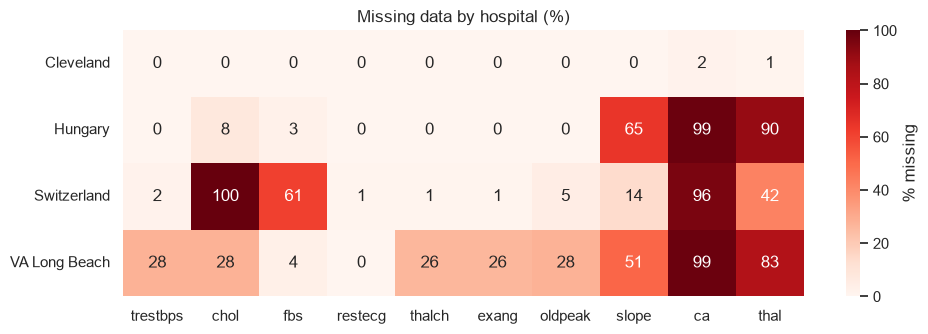

In [7]:
# Missing values by hospital (% of that hospital's patients)
check = df.copy()
check["chol"] = check["chol"].replace(0, np.nan)
cols = ["trestbps", "chol", "fbs", "restecg", "thalch", "exang", "oldpeak", "slope", "ca", "thal"]
missing_by_site = check.groupby("dataset")[cols].apply(lambda g: g.isnull().mean() * 100)

plt.figure(figsize=(10, 3.5))
sns.heatmap(missing_by_site, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% missing"})
plt.title("Missing data by hospital (%)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("images/missing_by_hospital.png", dpi=150)
plt.show()

**What to note:** missing data is not random; it depends on the hospital. Some hospitals simply didn't run certain tests (`ca`, `thal`), and some recorded cholesterol as 0 when it wasn't measured. This pattern is a good thing to mention in your README.

## 6. Clean the data

Decisions (write these in your README, because someone else might decide differently):
1. Cholesterol or blood pressure of **0 → missing** (physically impossible for a living patient).
2. **Drop `ca` and `thal`:** about two-thirds and half missing; filling in that much would mostly be guessing.
3. **Drop `id`, `num` and `dataset`** from the features (an ID, the answer itself, and the hospital).
4. Turn TRUE/FALSE columns into "yes"/"no" text so they are handled like other categories.
5. Remaining gaps are filled **inside the model pipeline** (step 9), so the fill values are learned only from training data.

In [8]:
clean = df.copy()
clean["chol"] = clean["chol"].replace(0, np.nan)
clean["trestbps"] = clean["trestbps"].replace(0, np.nan)

for col in ["fbs", "exang"]:
    clean[col] = clean[col].map({True: "yes", False: "no", "TRUE": "yes", "FALSE": "no",
                                 "True": "yes", "False": "no"})

NUMERIC = ["age", "trestbps", "chol", "thalch", "oldpeak"]
CATEGORICAL = ["sex", "cp", "fbs", "restecg", "exang", "slope"]

X = clean[NUMERIC + CATEGORICAL]
y = clean["disease"]
print("Features used:", NUMERIC + CATEGORICAL)
print("Missing values left (filled later in the pipeline):")
print(X.isnull().sum()[X.isnull().sum() > 0])

Features used: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope']
Missing values left (filled later in the pipeline):
trestbps     60
chol        202
thalch       55
oldpeak      62
fbs          90
restecg       2
exang        55
slope       309
dtype: int64


## 7. Exploratory data analysis (EDA)

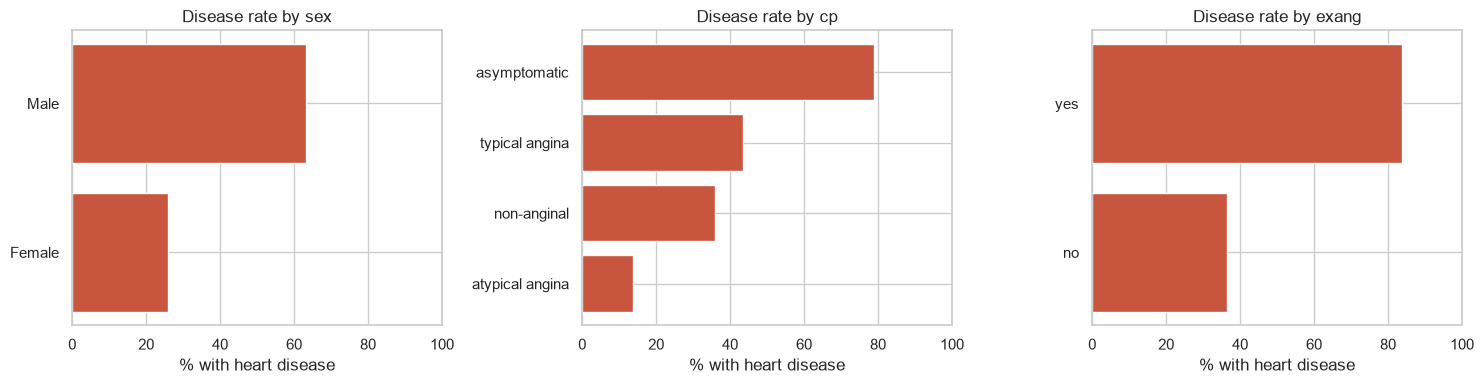

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["sex", "cp", "exang"]):
    rate = clean.groupby(col)["disease"].mean().sort_values() * 100
    ax.barh(rate.index.astype(str), rate.values, color="#C8553D")
    ax.set_xlim(0, 100)
    ax.set_xlabel("% with heart disease")
    ax.set_title(f"Disease rate by {col}")
plt.tight_layout()
plt.savefig("images/disease_rate_by_category.png", dpi=150)
plt.show()

**A surprise worth explaining:** patients with **asymptomatic** chest pain have the *highest* disease rate. Everyone here was referred for angiography, so a patient with no chest pain was likely sent for some other strong reason (an abnormal test, for example). This is a classic example of how *how patients were selected* shapes what a dataset shows, and a great interview talking point.

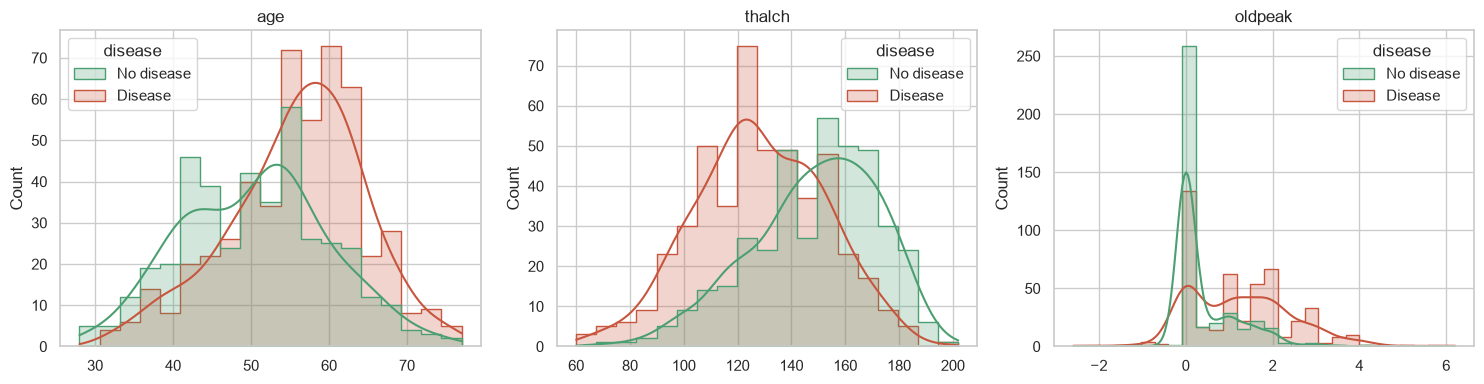

In [10]:
label = clean["disease"].map({0: "No disease", 1: "Disease"})
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "thalch", "oldpeak"]):
    sns.histplot(x=clean[col], hue=label, kde=True, element="step", ax=ax,
                 palette={"No disease": "#4C9F70", "Disease": "#C8553D"})
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("images/feature_distributions.png", dpi=150)
plt.show()

**What to note:** patients with disease tend to be older, reach a **lower maximum heart rate** (`thalch`) and show **more ST depression** (`oldpeak`) during exercise, all consistent with a heart that gets less blood under stress.

## 8. Split into training and test sets

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Training:", len(X_train), "| Test:", len(X_test))

Training: 736 | Test: 184


## 9. Build the preprocessing pipeline

- **Numbers:** fill gaps with the median (robust to outliers), then standardise.
- **Categories:** fill gaps with the label "missing", then **one-hot encode** (one yes/no column per category, since models need numbers).

Wrapping this in a `Pipeline` guarantees that medians and categories are learned from the training data only, then applied unchanged to the test data. Learning them from all data would be **data leakage**: the test set would secretly influence training.

In [12]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL),
])

log_reg = Pipeline([("prep", clone(preprocess)),
                    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
tree = Pipeline([("prep", clone(preprocess)),
                 ("model", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))])

## 10. Train and compare the models

In [13]:
log_reg.fit(X_train, y_train)
tree.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)
y_pred_tree = tree.predict(X_test)

def scores(name, y_true, y_pred):
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred)}

results = pd.DataFrame([scores("Logistic regression", y_test, y_pred_lr),
                        scores("Decision tree (depth 4)", y_test, y_pred_tree)]).set_index("Model")
results.round(3)

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic regression,0.842,0.841,0.882,0.861
Decision tree (depth 4),0.772,0.849,0.716,0.777


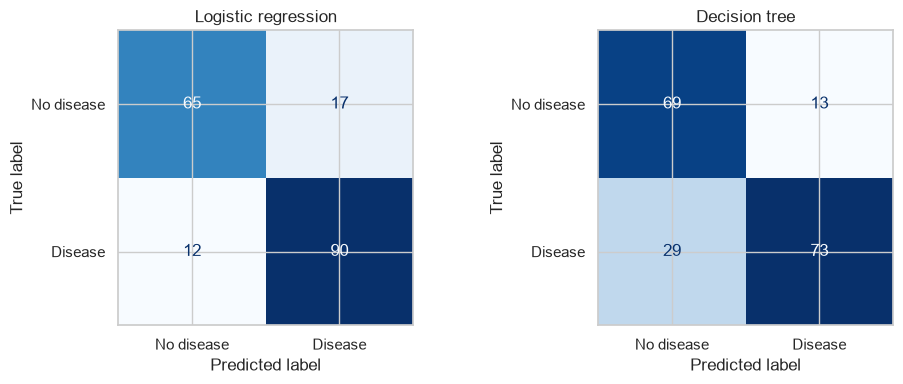

              precision    recall  f1-score   support

  No disease       0.84      0.79      0.82        82
     Disease       0.84      0.88      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.84      0.84       184
weighted avg       0.84      0.84      0.84       184



In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [("Logistic regression", y_pred_lr), ("Decision tree", y_pred_tree)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["No disease", "Disease"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("images/confusion_matrices.png", dpi=150)
plt.show()
print(classification_report(y_test, y_pred_lr, target_names=["No disease", "Disease"]))

The bottom-left cell of each matrix is **missed disease** (false negatives), the number we most want to be small.

## 11. Check stability with cross-validation

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in [("Logistic regression", log_reg), ("Decision tree (depth 4)", tree)]:
    for metric in ["accuracy", "recall"]:
        s = cross_val_score(model, X, y, cv=cv, scoring=metric)
        rows.append({"Model": name, "Metric": metric, "Mean": s.mean(), "Std": s.std()})
pd.DataFrame(rows).round(3)

,Model,Metric,Mean,Std
0,Logistic regression,accuracy,0.820,0.025
1,Logistic regression,recall,0.853,0.051
2,Decision tree (depth 4),accuracy,0.751,0.023
3,Decision tree (depth 4),recall,0.751,0.072


## 12. Which features matter?

After one-hot encoding, each category gets its own column (e.g. `cp_asymptomatic`). Positive logistic-regression coefficients push towards disease.

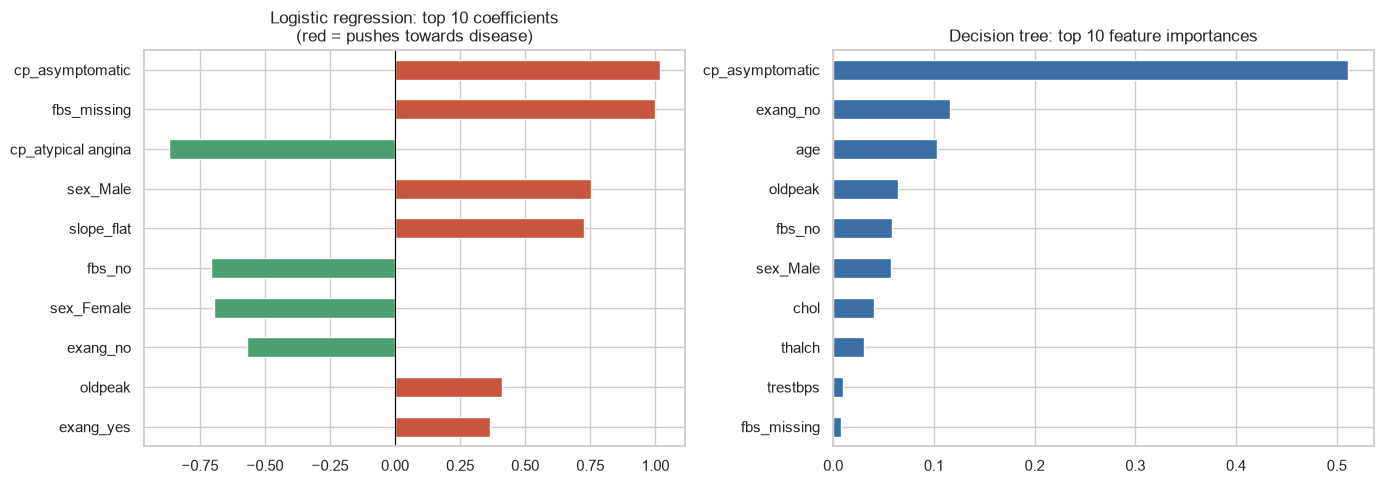

In [16]:
def clean_names(names):
    return [n.replace("num__", "").replace("cat__", "") for n in names]

lr_names = clean_names(log_reg.named_steps["prep"].get_feature_names_out())
coefs = pd.Series(log_reg.named_steps["model"].coef_[0], index=lr_names)
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

importances = pd.Series(tree.named_steps["model"].feature_importances_, index=lr_names)
importances = importances.sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_coefs[::-1].plot.barh(ax=axes[0], color=["#C8553D" if v > 0 else "#4C9F70" for v in top_coefs[::-1]])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Logistic regression: top 10 coefficients\n(red = pushes towards disease)")
importances[::-1].plot.barh(ax=axes[1], color="#3A6EA5")
axes[1].set_title("Decision tree: top 10 feature importances")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150)
plt.show()

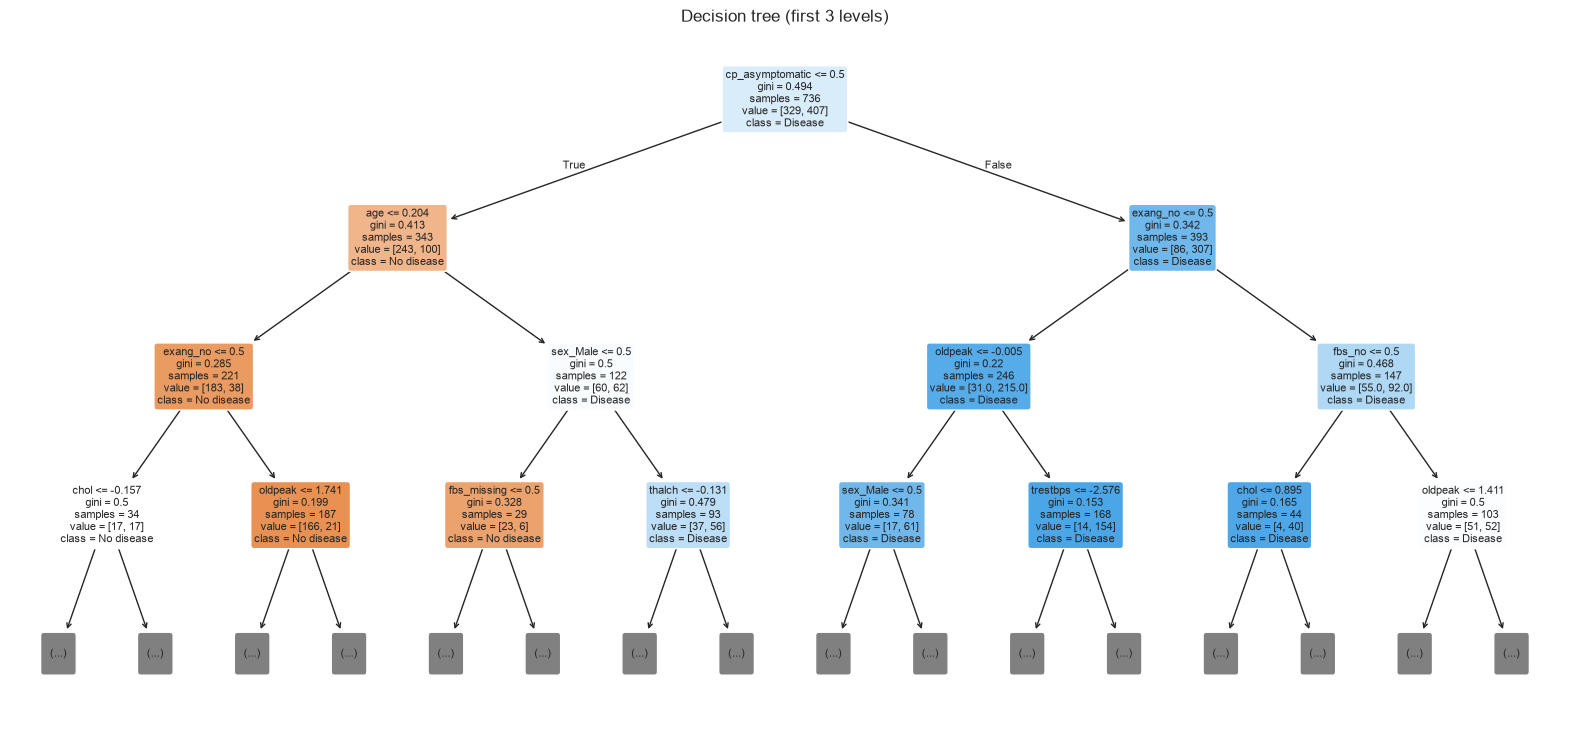

In [17]:
plt.figure(figsize=(20, 9))
plot_tree(tree.named_steps["model"], feature_names=lr_names, class_names=["No disease", "Disease"],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title("Decision tree (first 3 levels)")
plt.savefig("images/decision_tree.png", dpi=120, bbox_inches="tight")
plt.show()

**How to read this:** look for features both models agree on (typically chest pain type, exercise-induced angina, ST depression, max heart rate, sex). Treat exact rankings with caution; they can shift with a different random seed.

## 13. Does the model work at a hospital it has never seen?

This is the question a health-tech company would ask before using a model somewhere new. For each hospital, we train on the other three and test on it (*leave-one-hospital-out*).

Watch the sample sizes: Switzerland has very few healthy patients, so its accuracy mostly reflects how well the model catches disease, and its precision is not meaningful.

In [18]:
site_rows = []
for site in clean["dataset"].unique():
    train_mask = clean["dataset"] != site
    model = Pipeline([("prep", clone(preprocess)),
                      ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
    model.fit(X[train_mask], y[train_mask])
    pred = model.predict(X[~train_mask])
    site_rows.append({"Test hospital": site,
                      "Patients": int((~train_mask).sum()),
                      "% with disease": y[~train_mask].mean() * 100,
                      "Accuracy": accuracy_score(y[~train_mask], pred),
                      "Recall": recall_score(y[~train_mask], pred)})
site_results = pd.DataFrame(site_rows).set_index("Test hospital").round(3)
site_results

,Patients,% with disease,Accuracy,Recall
Test hospital,,,,
Cleveland,304,45.724,0.776,0.820
Hungary,293,36.177,0.809,0.821
Switzerland,123,93.496,0.764,0.774
VA Long Beach,200,74.500,0.740,0.812


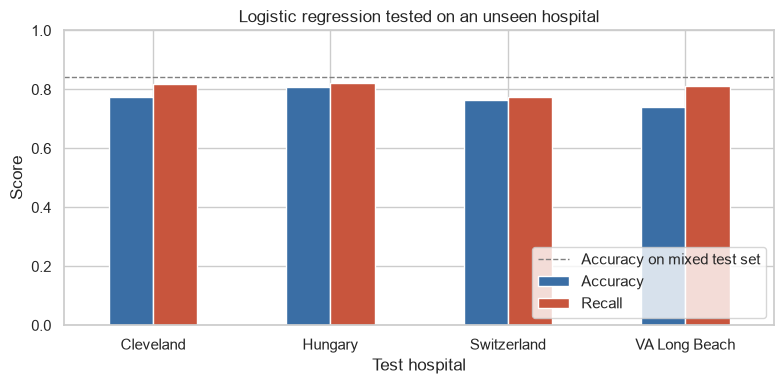

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
site_results[["Accuracy", "Recall"]].plot.bar(ax=ax, color=["#3A6EA5", "#C8553D"], rot=0)
ax.axhline(results.loc["Logistic regression", "Accuracy"], color="grey", linestyle="--", linewidth=1,
           label="Accuracy on mixed test set")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Logistic regression tested on an unseen hospital")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/unseen_hospital.png", dpi=150)
plt.show()

**What to note:** performance usually drops on at least one unseen hospital. Patients, equipment and recording habits differ between sites. This is called **dataset shift**, and spotting it is one of the most valuable things you can say about a medical model.

## 14. Catching more disease: adjusting the threshold

Lowering the probability cut-off catches more disease (higher recall) at the cost of more false alarms.

*Honest caveat:* we use the test set here only to illustrate the trade-off. In real work you choose the threshold on a separate validation set, because tuning on the test set makes results look better than they will be on new patients.

In [20]:
proba = log_reg.predict_proba(X_test)[:, 1]
rows = []
for t in [0.5, 0.4, 0.3, 0.2]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Threshold": t, "Recall": recall_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Missed disease (FN)": fn, "False alarms (FP)": fp})
pd.DataFrame(rows).round(3)

,Threshold,Recall,Precision,Missed disease (FN),False alarms (FP)
0,0.5,0.882,0.841,12,17
1,0.4,0.922,0.790,8,25
2,0.3,0.951,0.764,5,30
3,0.2,0.980,0.725,2,38


## 15. Conclusions

1. **Data cleaning:** 172 of 920 cholesterol values (18.7%) were recorded as 0 (every Swiss patient, plus 49 at VA Long Beach) and were treated as missing; `ca` and `thal` were dropped (66.4% and 52.8% missing). Missing data depended strongly on the hospital.
2. **Models:** logistic regression reached 84.2% accuracy and 0.88 recall for disease on the test set, vs 77.2% / 0.72 for the decision tree. 5-fold cross-validation agrees: 82.0% ± 2.5 vs 75.1% ± 2.3 accuracy.
3. **Key predictors:** asymptomatic chest pain, exercise-induced angina, ST depression (`oldpeak`) and male sex, consistent with clinical knowledge of coronary artery disease. One warning sign: *fasting blood sugar missing* is also a strong predictor, because it is mostly missing at Switzerland, where 93.5% of patients have disease. The hospital leaks back in through the missing-data pattern.
4. **Unseen hospital:** accuracy fell from 84.2% to 74.0% when testing on VA Long Beach (76.4% on Switzerland, 77.6% on Cleveland, 80.9% on Hungary), showing the model would need re-checking before use at a new site.
5. **Threshold:** lowering the cut-off from 0.5 to 0.3 cut missed disease cases from 12 to 5 (recall 0.88 → 0.95), at the cost of 13 more false alarms.

**Limitations:**
- Data from the 1980s at four sites; diagnosis methods and populations have changed.
- Every patient was already referred for angiography, so this is not a general-population screening sample.
- Missing values were filled with simple rules; other choices could change results.
- Small sample (920 patients). This is a learning project, **not a clinical tool**.
